In [1]:
from google.colab import files

uploaded = files.upload()

Saving Housing.csv to Housing.csv


Dataset shape: (545, 13)

First 5 rows:
      price  area  bedrooms  bathrooms  stories mainroad guestroom basement  \
0  13300000  7420         4          2        3      yes        no       no   
1  12250000  8960         4          4        4      yes        no       no   
2  12250000  9960         3          2        2      yes        no      yes   
3  12215000  7500         4          2        2      yes        no      yes   
4  11410000  7420         4          1        2      yes       yes      yes   

  hotwaterheating airconditioning  parking prefarea furnishingstatus  
0              no             yes        2      yes        furnished  
1              no             yes        3       no        furnished  
2              no              no        2      yes   semi-furnished  
3              no             yes        3      yes        furnished  
4              no             yes        2       no        furnished  

--- Model Performance ---
MAE: 1265275.67
RMSE: 1658324.6


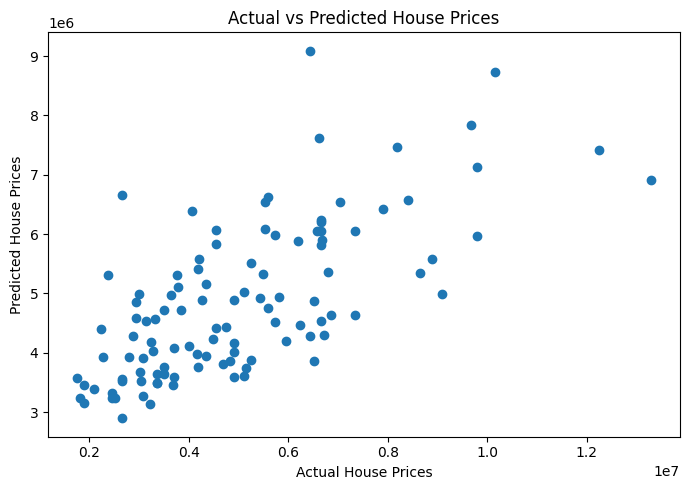

In [2]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Load the real dataset
df = pd.read_csv("Housing.csv")

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

# 2. Select features and target
X = df[["area", "bedrooms", "bathrooms"]]
y = df["price"]

# 3. Handle missing values
data = pd.concat([X, y], axis=1).dropna()
X = data[["area", "bedrooms", "bathrooms"]]
y = data["price"]

# 4. Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 5. Train Linear Regression
model = LinearRegression()
model.fit(X_train, y_train)

# 6. Predict house prices
y_pred = model.predict(X_test)

# 7. Evaluate model
print("\n--- Model Performance ---")
print("MAE:", round(mean_absolute_error(y_test, y_pred), 2))
print("RMSE:", round(mean_squared_error(y_test, y_pred) ** 0.5, 2))
print("R2 Score:", round(r2_score(y_test, y_pred), 4))

# 8. Predict price for a new house
new_house = pd.DataFrame({
    "area": [3000],
    "bedrooms": [3],
    "bathrooms": [2]
})

predicted_price = model.predict(new_house)[0]
print("\nPredicted price for new house:", round(predicted_price, 2))

# 9. Actual vs predicted visualization
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")
plt.tight_layout()
plt.show()
